# ASL Alphabet Recognition — Train Your Own Model (audited & corrected)

**Pipeline:** Kaggle ASL Alphabet images → OpenCV → MediaPipe hand detection → 21 landmarks / 63 features → **model selection with grouped cross-validation (Random Forest / Extra Trees / SVM, trained from scratch)** → held-out evaluation → live webcam recognition.

This notebook trains a new ASL letter classifier from the Kaggle images. It does **not** load any pretrained ASL classifier. The only downloaded model file is MediaPipe's hand-detection task file, which is not an ASL classifier.

### What this version changes compared with the first version (and why)
| Problem in the first version | Fix here |
|---|---|
| Random split of *consecutive video frames* → near-duplicate images in train and test (data leakage, optimistic accuracy) | Frames are grouped into contiguous blocks; train / validation / test splits never share a block. A leakage diagnostic compares random vs grouped splits. |
| Features not scale- or aspect-normalized (MediaPipe x/y are divided by image width/height) | Landmarks converted to pixels, made wrist-relative **and** divided by hand size. Still exactly 63 features. |
| Only one test accuracy number; no validation, CV, learning curves, tuning | Grouped CV, train / validation / test metrics, macro-F1, balanced accuracy, learning curves, per-letter results |
| Single fixed Random Forest | Random Forest vs Extra Trees vs SVM, small tuning grids, selection by CV macro-F1 (test set untouched) |
| Webcam mirroring / left-right hand mismatch | Mirror augmentation during training (train folds only) and mirroring disabled in the webcam widget |
| Arbitrary confidence thresholds | Thresholds calibrated on out-of-fold validation predictions, then checked once on the test set |

### Run instructions
1. Open in Google Colab and choose a runtime.
2. Run every cell from top to bottom. Upload your private `kaggle.json` when asked.
3. Feature extraction and model comparison take several minutes (feature extraction is cached in Drive).
4. Open the webcam section, allow Chrome camera permission, then select the webcam input.

**Scope:** static handshapes A–Z only. J and Z are movement signs; here they are classified from a single static frame.

## 1. Install required libraries

Run this cell once in a fresh Colab runtime. If Colab requests a runtime restart after installation, restart and continue from Section 2.

In [2]:
%pip -q install mediapipe gradio scikit-learn joblib kaggle opencv-python-headless

## 2. Mount Google Drive, import libraries and prepare project folders

In [3]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import os, re, json, time, random, zipfile, subprocess, urllib.request
from collections import Counter

import warnings
import cv2
import numpy as np
import matplotlib.pyplot as plt
import mediapipe as mp
import gradio as gr
import joblib
import sklearn

from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.model_selection import (
    train_test_split, StratifiedGroupKFold, GridSearchCV,
    cross_val_predict, learning_curve
)
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    precision_recall_fscore_support, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)

# Newer scikit-learn versions warn about SVC(probability=True); it still works and is only needed for the webcam confidence.
warnings.filterwarnings("ignore", category=FutureWarning, module=r"sklearn\.svm")

LETTERS = list("ABCDEFGHIJKLMNOPQRSTUVWXYZ")
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}
RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

PROJECT_DIR = Path("/content/asl_sign_language_project")
DOWNLOAD_DIR = Path("/content/asl_data")
DRIVE_PROJECT_DIR = Path("/content/drive/MyDrive/ASL_Project")
MODEL_DIR = DRIVE_PROJECT_DIR / "trained_models"
DATASET_DIR = DRIVE_PROJECT_DIR / "dataset"
HAND_MODEL_PATH = PROJECT_DIR / "hand_landmarker.task"
DATASET_PATH = DATASET_DIR / "asl_landmarks_v2_scaled.npz"
MODEL_PATH = MODEL_DIR / "asl_classifier_trained_from_kaggle.pkl"
META_PATH = MODEL_DIR / "asl_classifier_trained_from_kaggle_meta.json"

for folder in [PROJECT_DIR, DOWNLOAD_DIR, MODEL_DIR, DATASET_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("MediaPipe:", mp.__version__)
print("OpenCV:", cv2.__version__)
print("Gradio:", gr.__version__)
print("scikit-learn:", sklearn.__version__)
print("Project folders are ready.")
print("A new ASL classifier will be trained in this run.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
MediaPipe: 1.2.3
OpenCV: 5.0.0
Gradio: 6.31.0
scikit-learn: 1.6.1
Project folders are ready.
A new ASL classifier will be trained in this run.


## 3. Configure Kaggle API

Upload the `kaggle.json` file downloaded from your Kaggle account. The token is stored privately in the Colab runtime with restricted file permissions. This cell does not print the token.

In [4]:
from google.colab import files

KAGGLE_DIR = Path.home() / ".kaggle"
KAGGLE_FILE = KAGGLE_DIR / "kaggle.json"
KAGGLE_DIR.mkdir(parents=True, exist_ok=True)

if not KAGGLE_FILE.exists():
    print("Please upload your Kaggle API file: kaggle.json")
    uploaded = files.upload()

    kaggle_filename = next(
        (name for name in uploaded if name.lower().endswith(".json")),
        None
    )
    if kaggle_filename is None:
        raise FileNotFoundError("No kaggle.json was uploaded.")

    KAGGLE_FILE.write_bytes(uploaded[kaggle_filename])
    os.chmod(KAGGLE_FILE, 0o600)

print("Kaggle API configuration is ready.")

Please upload your Kaggle API file: kaggle.json


Saving kaggle.json to kaggle.json
Kaggle API configuration is ready.


## 4. Download and extract the ASL Alphabet dataset

Dataset: **grassknoted/asl-alphabet** on Kaggle. The training images are arranged in folders `A`–`Z` plus `del`, `nothing` and `space`. If a complete extraction already exists in this runtime, download and extraction are skipped. (The first version only checked that the folder existed; a half-finished extraction would have been silently accepted.)

In [5]:
ZIP_PATH = Path("/content/asl-alphabet.zip")

def find_train_dir(root):
    """Return the folder that contains all 26 letter sub-folders, or None."""
    for dirpath, dirnames, _ in os.walk(root):
        if all(letter in dirnames for letter in LETTERS):
            return Path(dirpath)
    return None

TRAIN_DIR = find_train_dir(DOWNLOAD_DIR)

if TRAIN_DIR is None:
    if not ZIP_PATH.exists():
        print("Downloading ASL Alphabet dataset from Kaggle...")
        result = subprocess.run(
            ["kaggle", "datasets", "download",
             "-d", "grassknoted/asl-alphabet", "-p", "/content", "-o"],
            capture_output=True, text=True
        )
        if result.returncode != 0:
            raise RuntimeError(
                "Kaggle download failed. Check your kaggle.json and internet access.\n"
                + result.stderr[-3000:]
            )
        downloaded_zips = list(Path("/content").glob("asl-alphabet*.zip"))
        if not downloaded_zips:
            raise FileNotFoundError("Kaggle download finished but the ZIP file was not found.")
        ZIP_PATH = downloaded_zips[0]

    print("Extracting dataset. This may take a few minutes...")
    with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
        zip_ref.extractall(DOWNLOAD_DIR)

    TRAIN_DIR = find_train_dir(DOWNLOAD_DIR)
    if TRAIN_DIR is None:
        raise FileNotFoundError(
            "Could not find the A-Z training folders after extraction. "
            "Please check the downloaded ZIP structure."
        )

print("Dataset ready:", TRAIN_DIR)

Extracting dataset. This may take a few minutes...
Dataset ready: /content/asl_data/asl_alphabet_train/asl_alphabet_train


## 5. Verify the image folders (A–Z used; `del`, `nothing`, `space` reported and excluded)

The three extra folders are **not** trained as classes. This is intentional for a letter classifier: Space / Delete are handled by buttons in the word builder, and "nothing" (no hand) is handled by MediaPipe returning no hand. Because there is no "nothing" class, a hand that is not a letter will be forced into the closest letter, which is why confidence thresholds are calibrated later.

In [6]:
all_folders = sorted(p.name for p in TRAIN_DIR.iterdir() if p.is_dir())
included = [f for f in all_folders if f in LETTERS]
excluded = [f for f in all_folders if f not in LETTERS]

missing_letters = [l for l in LETTERS if l not in all_folders]
if missing_letters:
    raise FileNotFoundError(f"Missing dataset folders for letters: {missing_letters}")

print(f"Folders found: {len(all_folders)}")
print("Trained classes   :", "".join(included), f"({len(included)} letters)")
print("Excluded folders  :", excluded)

image_counts = {}
for folder in all_folders:
    image_counts[folder] = sum(
        1 for f in (TRAIN_DIR / folder).iterdir()
        if f.is_file() and f.suffix.lower() in IMAGE_EXTENSIONS
    )

print("\nImages per folder:")
for folder in all_folders:
    tag = "" if folder in LETTERS else "   (excluded)"
    print(f"  {folder:>8}: {image_counts[folder]}{tag}")

letter_counts = [image_counts[l] for l in LETTERS]
print("\nLetter images total :", sum(letter_counts))
print("Smallest / largest letter folder:", min(letter_counts), "/", max(letter_counts))
print("Class imbalance ratio (max/min) :", round(max(letter_counts) / max(1, min(letter_counts)), 3))

def frame_number(path):
    """Numeric part of file names such as A123.jpg (None if there is none)."""
    found = re.findall(r"\d+", path.stem)
    return int(found[-1]) if found else None

sample_files = sorted((TRAIN_DIR / "A").iterdir(), key=lambda p: (frame_number(p) or 0))[:3]
print("\nExample file names:", [p.name for p in sample_files])
parsed = sum(frame_number(p) is not None for p in (TRAIN_DIR / "A").iterdir())
print(f"File names with a numeric frame id (folder A): {parsed}/{image_counts['A']}")

sample_img = cv2.imread(str(sample_files[0]))
print("Image size (H, W, C):", None if sample_img is None else sample_img.shape)

Folders found: 29
Trained classes   : ABCDEFGHIJKLMNOPQRSTUVWXYZ (26 letters)
Excluded folders  : ['del', 'nothing', 'space']

Images per folder:
         A: 3000
         B: 3000
         C: 3000
         D: 3000
         E: 3000
         F: 3000
         G: 3000
         H: 3000
         I: 3000
         J: 3000
         K: 3000
         L: 3000
         M: 3000
         N: 3000
         O: 3000
         P: 3000
         Q: 3000
         R: 3000
         S: 3000
         T: 3000
         U: 3000
         V: 3000
         W: 3000
         X: 3000
         Y: 3000
         Z: 3000
       del: 3000   (excluded)
   nothing: 3000   (excluded)
     space: 3000   (excluded)

Letter images total : 78000
Smallest / largest letter folder: 3000 / 3000
Class imbalance ratio (max/min) : 1.0

Example file names: ['A1.jpg', 'A2.jpg', 'A3.jpg']
File names with a numeric frame id (folder A): 3000/3000
Image size (H, W, C): (200, 200, 3)


## 6. Download and initialize MediaPipe Hand Landmarker

MediaPipe detects one hand and returns 21 landmarks. The same detector settings are used for dataset images and webcam frames.

In [7]:
if not HAND_MODEL_PATH.exists() or HAND_MODEL_PATH.stat().st_size < 1_000_000:
    hand_model_url = (
        "https://storage.googleapis.com/mediapipe-models/"
        "hand_landmarker/hand_landmarker/float16/1/hand_landmarker.task"
    )
    urllib.request.urlretrieve(hand_model_url, HAND_MODEL_PATH)

def create_hand_detector():
    options = mp.tasks.vision.HandLandmarkerOptions(
        base_options=mp.tasks.BaseOptions(
            model_asset_path=str(HAND_MODEL_PATH)
        ),
        running_mode=mp.tasks.vision.RunningMode.IMAGE,
        num_hands=1,
        min_hand_detection_confidence=0.5,
        min_hand_presence_confidence=0.5
    )
    return mp.tasks.vision.HandLandmarker.create_from_options(options)

detector = create_hand_detector()
print("MediaPipe Hand Landmarker is ready.")
print("Model file size:", round(HAND_MODEL_PATH.stat().st_size / (1024 * 1024), 2), "MB")

MediaPipe Hand Landmarker is ready.
Model file size: 7.46 MB


## 7. OpenCV + MediaPipe feature extraction (63 features)

**Feature format:** 21 landmarks × (x, y, z) = **63 features**, built in three steps:
1. MediaPipe x/y are fractions of image width/height, so they are converted to **pixels** first (otherwise a 640×480 webcam frame distorts the hand shape compared with the square 200×200 training images).
2. Every landmark is made **wrist-relative** (subtract landmark 0), as before.
3. Everything is divided by the **hand size** (mean wrist→MCP distance of the four fingers), so the features no longer depend on how close the hand is to the camera.

Rotation is deliberately *not* normalized because hand orientation matters for letters such as G/H and P/Q.

If the first detection fails, detection is retried once on a black-padded copy of the image (the dataset images are tightly cropped around the hand). Landmark coordinates are shifted back to the original image, so training and webcam use exactly the same code path.

- Dataset image: OpenCV reads BGR, then converts it to RGB.
- Webcam frame from Gradio: already RGB, so it is not converted from BGR.

In [8]:
PAD_PIXELS = 60
SCALE_LANDMARKS = (5, 9, 13, 17)   # finger base (MCP) joints

def detect_landmarks_px(rgb_image, pad_retry=True):
    """Return a (21, 3) array of landmarks in PIXEL units of the given image, or None."""
    if rgb_image is None:
        return None
    rgb = np.asarray(rgb_image, dtype=np.uint8)
    if rgb.ndim != 3 or rgb.shape[2] < 3:
        return None
    rgb = np.ascontiguousarray(rgb[:, :, :3])

    for pad in ([0, PAD_PIXELS] if pad_retry else [0]):
        if pad:
            image = cv2.copyMakeBorder(rgb, pad, pad, pad, pad,
                                       cv2.BORDER_CONSTANT, value=(0, 0, 0))
        else:
            image = rgb
        image = np.ascontiguousarray(image)
        height, width = image.shape[:2]

        result = detector.detect(
            mp.Image(image_format=mp.ImageFormat.SRGB, data=image)
        )
        if result.hand_landmarks and len(result.hand_landmarks[0]) == 21:
            return np.array(
                [[p.x * width - pad, p.y * height - pad, p.z * width]
                 for p in result.hand_landmarks[0]],
                dtype=np.float32
            )
    return None


def landmarks_to_features(points_px):
    """(21, 3) pixel landmarks -> 63 wrist-relative, size-normalized features."""
    if points_px is None or np.shape(points_px) != (21, 3):
        return None

    relative = points_px - points_px[0]
    hand_size = float(np.mean(
        np.linalg.norm(relative[list(SCALE_LANDMARKS), :2], axis=1)
    ))
    if not np.isfinite(hand_size) or hand_size < 2.0:
        return None

    features = (relative / hand_size).astype(np.float32).ravel()
    if features.shape != (63,) or not np.isfinite(features).all():
        return None
    return features


def mirror_features(feature_matrix):
    """Horizontal mirror of hand features (x -> -x). Used for training augmentation."""
    mirrored = np.array(feature_matrix, dtype=np.float32, copy=True).reshape(-1, 21, 3)
    mirrored[:, :, 0] *= -1.0
    return mirrored.reshape(-1, 63)


def extract_features_from_rgb(rgb_image):
    """Single entry point used for training images AND webcam frames."""
    points = detect_landmarks_px(rgb_image)
    if points is None:
        return None, None
    return landmarks_to_features(points), points


def extract_features_from_file(image_path):
    image_bgr = cv2.imread(str(image_path))
    if image_bgr is None:
        return None
    image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
    features, _ = extract_features_from_rgb(image_rgb)
    return features


print("Feature extraction functions are ready.")

Feature extraction functions are ready.


## 8. Build the training dataset from Kaggle images (with source groups)

**Sampling:** the Kaggle images are *consecutive frames* of short videos (file names `A1.jpg … A3000.jpg`), so neighbouring images are almost identical. To get more variety than a random draw, frames are taken **evenly spaced** across each letter's sorted frame list. Each sample also gets a **group id** = letter + block of `BLOCK_SIZE` consecutive frames. Groups are used later so that near-identical neighbouring frames never end up in both training and test data.

Reported per letter: how many images MediaPipe could not detect a hand in (those images are dropped; a high failure rate for one letter would bias the model).

Features are cached in Drive and reused only if the settings and `FEATURE_VERSION` match. Set `FORCE_REEXTRACT = True` to rebuild.

Starting feature extraction from Kaggle images...

Class A: 463/600 images with a detected hand (77.2%)
Class B: 452/600 images with a detected hand (75.3%)
Class C: 450/600 images with a detected hand (75.0%)
Class D: 533/600 images with a detected hand (88.8%)
Class E: 475/600 images with a detected hand (79.2%)
Class F: 594/600 images with a detected hand (99.0%)
Class G: 520/600 images with a detected hand (86.7%)
Class H: 504/600 images with a detected hand (84.0%)
Class I: 509/600 images with a detected hand (84.8%)
Class J: 545/600 images with a detected hand (90.8%)
Class K: 561/600 images with a detected hand (93.5%)
Class L: 546/600 images with a detected hand (91.0%)
Class M: 423/600 images with a detected hand (70.5%)
Class N: 360/600 images with a detected hand (60.0%)
Class O: 508/600 images with a detected hand (84.7%)
Class P: 453/600 images with a detected hand (75.5%)
Class Q: 485/600 images with a detected hand (80.8%)
Class R: 538/600 images with a detected hand (89

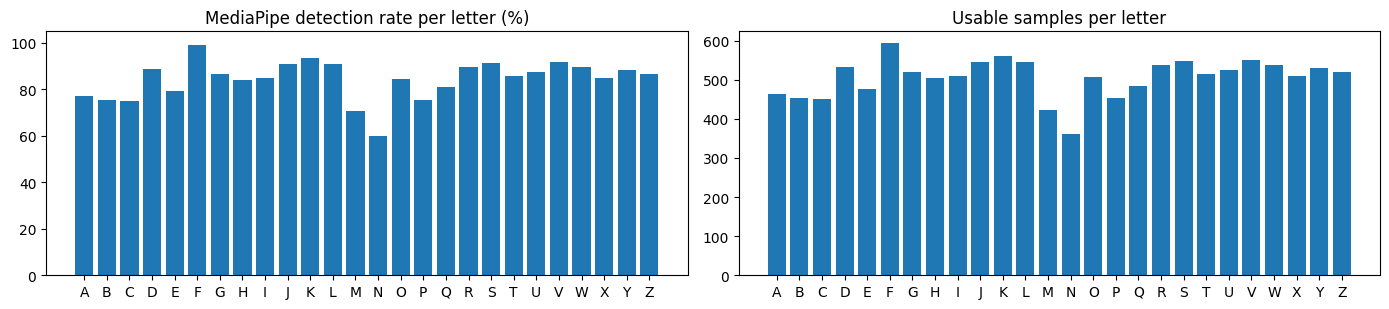

In [9]:
FEATURE_VERSION = "v2_px_wristrel_handsize"
SAMPLES_PER_LETTER = 600      # evenly spaced frames per letter (3000 available)
BLOCK_SIZE = 150              # consecutive frames per group (≈ one short video segment)
FORCE_REEXTRACT = False

cache_ok = False
if DATASET_PATH.exists() and not FORCE_REEXTRACT:
    cache = np.load(DATASET_PATH, allow_pickle=False)
    if (str(cache["feature_version"]) == FEATURE_VERSION
            and int(cache["samples_per_letter"]) == SAMPLES_PER_LETTER
            and int(cache["block_size"]) == BLOCK_SIZE):
        X, y, groups = cache["X"], cache["y"], cache["groups"]
        frame_ids, attempted = cache["frame_ids"], cache["attempted"]
        n_dropped_duplicates = int(cache["n_dropped_duplicates"])
        cache_ok = True
        print("Loaded cached features built with the same settings:", DATASET_PATH)

if not cache_ok:
    print("Starting feature extraction from Kaggle images...\n")
    X_values, y_values, group_values, frame_values = [], [], [], []
    attempted_list = []

    for letter in LETTERS:
        files = [p for p in (TRAIN_DIR / letter).iterdir()
                 if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS]
        if not files:
            raise FileNotFoundError(f"No images found for class {letter}")
        files.sort(key=lambda p: (frame_number(p) if frame_number(p) is not None else -1, p.name))

        picks = np.unique(np.linspace(
            0, len(files) - 1, min(SAMPLES_PER_LETTER, len(files))
        ).round().astype(int))

        usable = 0
        for rank in picks:
            features = extract_features_from_file(files[rank])
            if features is None:
                continue
            number = frame_number(files[rank])
            X_values.append(features)
            y_values.append(letter)
            frame_values.append(number if number is not None else int(rank))
            group_values.append(f"{letter}_{int(rank) // BLOCK_SIZE:02d}")
            usable += 1

        attempted_list.append(len(picks))
        print(f"Class {letter}: {usable}/{len(picks)} images with a detected hand "
              f"({100 * usable / len(picks):.1f}%)")

    X = np.asarray(X_values, dtype=np.float32)
    y = np.asarray(y_values, dtype=str)
    groups = np.asarray(group_values, dtype=str)
    frame_ids = np.asarray(frame_values, dtype=np.int64)
    attempted = np.asarray(attempted_list, dtype=np.int64)

    if X.ndim != 2 or X.shape[1] != 63 or not (len(X) == len(y) == len(groups)):
        raise ValueError(f"Feature extraction produced an invalid dataset: X={X.shape}, y={y.shape}")

    # Remove exact duplicates (identical landmark vectors after rounding).
    _, keep = np.unique(np.round(X, 3), axis=0, return_index=True)
    keep = np.sort(keep)
    n_dropped_duplicates = len(X) - len(keep)
    X, y, groups, frame_ids = X[keep], y[keep], groups[keep], frame_ids[keep]

    np.savez_compressed(
        DATASET_PATH, X=X, y=y, groups=groups, frame_ids=frame_ids, attempted=attempted,
        feature_version=np.array(FEATURE_VERSION), samples_per_letter=np.array(SAMPLES_PER_LETTER),
        block_size=np.array(BLOCK_SIZE), n_dropped_duplicates=np.array(n_dropped_duplicates)
    )
    print("\nFeature dataset saved:", DATASET_PATH)

# ---- Dataset summary (runs for both fresh extraction and cache) ----
counts = Counter(y)
missing = [l for l in LETTERS if counts[l] < 20]
if missing:
    raise ValueError("Too few detected hand images for: " + ", ".join(missing))

print("\nFeature matrix:", X.shape, "| exact duplicates removed:", n_dropped_duplicates)
print("Groups (frame blocks):", len(np.unique(groups)))

detect_rate = np.array([counts[l] / max(1, a) for l, a in zip(LETTERS, attempted)])
print("Lowest MediaPipe detection rates:",
      {LETTERS[i]: f"{detect_rate[i]*100:.0f}%" for i in np.argsort(detect_rate)[:5]})
low = [LETTERS[i] for i in range(26) if detect_rate[i] < 0.70]
if low:
    print("WARNING: letters with <70% detection (their training data is thin / biased):", low)

fig, axes = plt.subplots(1, 2, figsize=(14, 3.2))
axes[0].bar(LETTERS, detect_rate * 100); axes[0].set_ylim(0, 105)
axes[0].set_title("MediaPipe detection rate per letter (%)")
axes[1].bar(LETTERS, [counts[l] for l in LETTERS]); axes[1].set_title("Usable samples per letter")
plt.tight_layout(); plt.show()

## 9. Leakage check and train / validation / test design

**Why this matters.** If neighbouring video frames are split randomly, a "test" image almost always has a near-identical twin in the training set, so test accuracy mostly measures memorisation, not generalisation.

This cell (1) measures the effect by comparing a **random** stratified split (the first version's method) with a **grouped** split, and (2) creates the final design:

- **Test set (about 20 %)**: whole frame blocks, never used for training, tuning or threshold selection.
- **Development set (about 80 %)**: used with **grouped stratified 5-fold cross-validation** for validation scores, model selection and tuning.

The leakage diagnostic uses one fixed fast model and is **not** used to pick a model.

**Limit that no split can remove:** this dataset comes from very few signers with a uniform background and camera, so even a grouped split cannot prove generalisation to new people or webcams. That is why Section 16 offers a test on your own photos.

In [ ]:
N_SPLITS = 5

groups_per_class = Counter()
for g in np.unique(groups):
    groups_per_class[g.split("_")[0]] += 1
if min(groups_per_class.values()) < N_SPLITS + 2:
    raise ValueError(
        f"Too few frame blocks per letter ({dict(groups_per_class)}). "
        "Increase SAMPLES_PER_LETTER or reduce BLOCK_SIZE and re-extract."
    )

index = np.arange(len(y))

# (a) Random stratified split - the original method
train_random, test_random = train_test_split(
    index, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

# (b) Grouped stratified split - blocks of consecutive frames never cross
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
dev_index, test_index = next(splitter.split(X, y, groups))

assert set(groups[dev_index]).isdisjoint(set(groups[test_index])), "Group leakage!"

def quick_probe(train_idx, test_idx):
    probe = ExtraTreesClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)
    probe.fit(X[train_idx], y[train_idx])
    accuracy = accuracy_score(y[test_idx], probe.predict(X[test_idx]))
    nearest = NearestNeighbors(n_neighbors=1).fit(X[train_idx]).kneighbors(X[test_idx])[0].ravel()
    return accuracy, float(np.median(nearest))

acc_random, nn_random = quick_probe(train_random, test_random)
acc_grouped, nn_grouped = quick_probe(dev_index, test_index)

print("LEAKAGE DIAGNOSTIC (same fast model, different split)")
print(f"  Random split : accuracy {acc_random*100:6.2f}% | median distance test→nearest train sample {nn_random:.4f}")
print(f"  Grouped split: accuracy {acc_grouped*100:6.2f}% | median distance test→nearest train sample {nn_grouped:.4f}")
print(f"  Accuracy drop when leakage is removed: {(acc_random-acc_grouped)*100:.2f} percentage points")
if acc_random - acc_grouped > 0.02 or nn_grouped > 1.5 * nn_random:
    print("  → Random splitting was optimistic: near-duplicate frames crossed the split.")
else:
    print("  → No strong leakage signal between the two splits for this sample.")

# Final design
X_dev, y_dev, g_dev = X[dev_index], y[dev_index], groups[dev_index]
X_test, y_test, g_test = X[test_index], y[test_index], groups[test_index]
cv = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)

print(f"\nDevelopment set: {len(y_dev)} samples, {len(np.unique(g_dev))} groups (used for CV / tuning)")
print(f"Held-out test  : {len(y_test)} samples, {len(np.unique(g_test))} groups (touched once, at the end)")
print("Smallest class in test set:", min(Counter(y_test).values()), "samples")

In [11]:
from sklearn.model_selection import StratifiedGroupKFold

# Create group-aware cross-validation
cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Cross-validation initialized successfully!")
print("Number of folds: 5")

Cross-validation initialized successfully!
Number of folds: 5


## 10. Model comparison with grouped cross-validation (Random Forest, Extra Trees, SVM)

All three candidates are trained **from scratch** on the development set only. Each gets a small tuning grid (the number of trees is fixed at 200, not blindly increased). Scores come from grouped 5-fold CV; `return_train_score=True` shows the **training vs validation gap** for every candidate.

**Selection rule (decided before looking at the test set):** highest CV macro-F1. If several models are within 0.5 percentage points, the one with the **smaller train–validation gap** wins. Balanced accuracy and the worst single-letter F1 are shown too.

**Mirror augmentation:** inside each training fold, a mirrored copy of every sample is added (x → −x). This makes the model robust to left-handed signers and to mirrored webcam feeds. Validation folds and the test set are never augmented.

*Run time depends on the Colab CPU (the SVM search is the slowest part; several minutes in total is expected).*

In [13]:

# ============================================================
# ASL SIGN RECOGNITION - MODEL TRAINING AND COMPARISON
# Random Forest | Extra Trees | SVM
# Group-aware validation to prevent data leakage
# ============================================================

import numpy as np
import pandas as pd
import time

from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.svm import SVC

from sklearn.model_selection import (
    StratifiedGroupKFold,
    GridSearchCV,
    cross_val_predict
)

from sklearn.metrics import (
    f1_score,
    accuracy_score,
    balanced_accuracy_score
)

# ------------------------------------------------------------
# 1. CONNECT YOUR EXISTING FEATURE DATA
# ------------------------------------------------------------

# These three variables must contain your complete feature data.
# Change their right-hand sides if your notebook uses other names.

X_all = X
y_all = y
groups_all = groups

X_all = np.asarray(X_all, dtype=np.float32)
y_all = np.asarray(y_all)
groups_all = np.asarray(groups_all)

assert X_all.ndim == 2 and X_all.shape[1] == 63, \
    "Expected 63 landmark features per sample."

assert len(X_all) == len(y_all) == len(groups_all), \
    "Features, labels and groups must have equal lengths."

print("Feature shape:", X_all.shape)
print("Classes:", np.unique(y_all))
print("Groups:", len(np.unique(groups_all)))

# ------------------------------------------------------------
# 2. CREATE GROUP-AWARE DEVELOPMENT AND TEST SETS
# ------------------------------------------------------------

outer_cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

dev_indices, test_indices = next(
    outer_cv.split(X_all, y_all, groups_all)
)

X_dev = X_all[dev_indices]
y_dev = y_all[dev_indices]
g_dev = groups_all[dev_indices]

X_test = X_all[test_indices]
y_test = y_all[test_indices]
g_test = groups_all[test_indices]

assert set(g_dev).isdisjoint(set(g_test)), \
    "Data leakage detected between development and test groups!"

print("\nDevelopment samples:", len(X_dev))
print("Test samples:", len(X_test))
print("Development groups:", len(np.unique(g_dev)))
print("Test groups:", len(np.unique(g_test)))
print("Group leakage: ZERO")

# ------------------------------------------------------------
# 3. MIRROR FEATURE AUGMENTATION
# ------------------------------------------------------------

USE_MIRROR_AUGMENTATION = True

def mirror_features(X):
    X = np.asarray(X, dtype=np.float32).copy()

    if X.shape[1] != 63:
        raise ValueError("Expected 63 features.")

    landmarks = X.reshape(-1, 21, 3)

    # Reflect the horizontal coordinate.
    landmarks[:, :, 0] *= -1

    return landmarks.reshape(-1, 63)


class MirrorAugmented(ClassifierMixin, BaseEstimator):

    def __init__(self, estimator=None, augment=True):
        self.estimator = estimator
        self.augment = augment

    def fit(self, X, y):

        X = np.asarray(X, dtype=np.float32)
        y = np.asarray(y)

        if self.augment:
            X = np.vstack([X, mirror_features(X)])
            y = np.concatenate([y, y])

        self.estimator_ = clone(self.estimator)
        self.estimator_.fit(X, y)

        self.classes_ = self.estimator_.classes_

        return self

    def predict(self, X):
        return self.estimator_.predict(X)

    def predict_proba(self, X):
        return self.estimator_.predict_proba(X)


# ------------------------------------------------------------
# 4. DEFINE MODEL CANDIDATES
# ------------------------------------------------------------

RANDOM_STATE = 42

forest_grid = {
    "estimator__min_samples_leaf": [1, 4],
    "estimator__max_features": ["sqrt", 0.3]
}

candidates = {

    "RandomForest": (
        RandomForestClassifier(
            n_estimators=200,
            class_weight="balanced",
            random_state=RANDOM_STATE,
            n_jobs=1
        ),
        forest_grid
    ),

    "ExtraTrees": (
        ExtraTreesClassifier(
            n_estimators=200,
            class_weight="balanced",
            random_state=RANDOM_STATE,
            n_jobs=1
        ),
        forest_grid
    ),

    "SVM": (
        Pipeline([
            ("scaler", StandardScaler()),
            ("svc", SVC(
                kernel="rbf",
                class_weight="balanced",
                random_state=RANDOM_STATE
            ))
        ]),
        {
            "estimator__svc__C": [3, 30],
            "estimator__svc__gamma": ["scale", 0.05]
        }
    )
}

# ------------------------------------------------------------
# 5. GROUP-AWARE CROSS VALIDATION
# ------------------------------------------------------------

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

scoring = {
    "macro_f1": "f1_macro",
    "balanced_acc": "balanced_accuracy",
    "accuracy": "accuracy"
}

search_results = {}

# ------------------------------------------------------------
# 6. TRAIN AND COMPARE MODELS
# ------------------------------------------------------------

for name, (base_estimator, grid) in candidates.items():

    print("\nTraining:", name)

    start = time.time()

    model = MirrorAugmented(
        estimator=base_estimator,
        augment=USE_MIRROR_AUGMENTATION
    )

    search = GridSearchCV(
        estimator=model,
        param_grid=grid,
        scoring=scoring,
        refit="macro_f1",
        cv=cv,
        n_jobs=-1,
        return_train_score=True,
        verbose=1
    )

    # Groups are essential for leakage-safe validation.
    search.fit(
        X_dev,
        y_dev,
        groups=g_dev
    )

    best_index = search.best_index_
    results = search.cv_results_

    # Out-of-fold predictions for per-class evaluation.
    oof_pred = cross_val_predict(
        search.best_estimator_,
        X_dev,
        y_dev,
        groups=g_dev,
        cv=cv,
        n_jobs=-1
    )

    labels = np.unique(y_dev)

    per_class_f1 = f1_score(
        y_dev,
        oof_pred,
        labels=labels,
        average=None,
        zero_division=0
    )

    search_results[name] = {

        "search": search,

        "params": search.best_params_,

        "train_f1": results[
            "mean_train_macro_f1"
        ][best_index],

        "val_f1": results[
            "mean_test_macro_f1"
        ][best_index],

        "val_f1_std": results[
            "std_test_macro_f1"
        ][best_index],

        "train_acc": results[
            "mean_train_accuracy"
        ][best_index],

        "val_acc": results[
            "mean_test_accuracy"
        ][best_index],

        "val_bal_acc": results[
            "mean_test_balanced_acc"
        ][best_index],

        "worst_letter": str(labels[np.argmin(per_class_f1)]),

        "worst_f1": float(per_class_f1.min()),

        "seconds": time.time() - start
    }

    print(
        f"{name} completed in "
        f"{search_results[name]['seconds']:.1f} seconds"
    )

# ------------------------------------------------------------
# 7. DISPLAY MODEL COMPARISON
# ------------------------------------------------------------

print("\n" + "=" * 100)

print(
    f"{'Model':<13}"
    f"{'Train F1':>10}"
    f"{'Val F1':>10}"
    f"{'Std':>8}"
    f"{'Gap':>8}"
    f"{'Val Acc':>10}"
    f"{'Bal Acc':>10}"
    f"{'Worst Class':>14}"
)

for name, result in search_results.items():

    gap = result["train_f1"] - result["val_f1"]

    print(
        f"{name:<13}"
        f"{result['train_f1'] * 100:>9.2f}%"
        f"{result['val_f1'] * 100:>9.2f}%"
        f"{result['val_f1_std'] * 100:>7.2f}%"
        f"{gap * 100:>7.2f}%"
        f"{result['val_acc'] * 100:>9.2f}%"
        f"{result['val_bal_acc'] * 100:>9.2f}%"
        f"{result['worst_letter']:>10}"
    )

print("=" * 100)

# ------------------------------------------------------------
# 8. SELECT BEST MODEL USING VALIDATION PERFORMANCE
# ------------------------------------------------------------

best_val = max(
    result["val_f1"]
    for result in search_results.values()
)

contenders = [
    name for name, result in search_results.items()
    if best_val - result["val_f1"] <= 0.005
]

best_name = min(
    contenders,
    key=lambda name:
        search_results[name]["train_f1"]
        - search_results[name]["val_f1"]
)

best_model = search_results[best_name]["search"].best_estimator_

print("\nSelected model:", best_name)
print("Best parameters:", search_results[best_name]["params"])

print("\nDevelopment training and model selection completed.")
print("The test dataset has NOT been used for model selection.")


Feature shape: (13150, 63)
Classes: ['A' 'B' 'C' 'D' 'E' 'F' 'G' 'H' 'I' 'J' 'K' 'L' 'M' 'N' 'O' 'P' 'Q' 'R'
 'S' 'T' 'U' 'V' 'W' 'X' 'Y' 'Z']
Groups: 503

Development samples: 10577
Test samples: 2573
Development groups: 401
Test groups: 102
Group leakage: ZERO

Training: RandomForest
Fitting 5 folds for each of 4 candidates, totalling 20 fits
RandomForest completed in 1591.6 seconds

Training: ExtraTrees
Fitting 5 folds for each of 4 candidates, totalling 20 fits
ExtraTrees completed in 165.8 seconds

Training: SVM
Fitting 5 folds for each of 4 candidates, totalling 20 fits
SVM completed in 263.0 seconds

Model          Train F1    Val F1     Std     Gap   Val Acc   Bal Acc   Worst Class
RandomForest    100.00%    91.57%   1.03%   8.43%    92.30%    92.48%         U
ExtraTrees      100.00%    93.26%   0.64%   6.74%    93.95%    94.06%         U
SVM              99.74%    96.18%   0.56%   3.56%    96.73%    96.65%         N

Selected model: SVM
Best parameters: {'estimator__svc__C': 3

In [16]:
# Recover selected model parameters

best_name = "SVM"

best_params = search_results[best_name]["params"]

print("Selected model:", best_name)
print("Best parameters:", best_params)

Selected model: SVM
Best parameters: {'estimator__svc__C': 30, 'estimator__svc__gamma': 'scale'}


In [17]:
final_wrapper.set_params(**best_params)

MirrorAugmented(estimator=Pipeline(steps=[('scaler', StandardScaler()),
                                          ('svc',
                                           SVC(C=30, class_weight='balanced',
                                               random_state=42))]))

In [18]:
import time

print("SVM training started...")

start = time.time()

final_wrapper.fit(X_dev, y_dev)

print("SVM training completed!")
print("Time taken:", round(time.time() - start, 2), "seconds")

model = final_wrapper.estimator_

print("Input features:", model.n_features_in_)
print("Classes:", model.classes_)

SVM training started...
SVM training completed!
Time taken: 8.4 seconds
Input features: 63
Classes: ['A' 'B' 'C' 'D' 'E' 'F' 'G' 'H' 'I' 'J' 'K' 'L' 'M' 'N' 'O' 'P' 'Q' 'R'
 'S' 'T' 'U' 'V' 'W' 'X' 'Y' 'Z']


## 11. Train the final model and evaluate it (training, validation and held-out test)

The selected configuration is refitted on the **entire development set** and evaluated **once** on the untouched test set. The three accuracy levels are:

- **Training:** performance on the data the model was fitted on.
- **Validation:** grouped cross-validation on the development set (out-of-fold, from Section 10).
- **Test:** the held-out frame blocks.

If the SVM wins, it is refitted with probability estimates enabled (the webcam code needs `predict_proba`).

## 12. Learning curves (training vs validation)

The curve uses grouped cross-validation on the development set with the selected configuration.

How to read it:
- **Both curves low** → underfitting.
- **Training high, validation much lower, gap not closing** → overfitting.
- **Validation curve levelling out close to the training curve** → the model generalises and more of the *same* data will not help much.

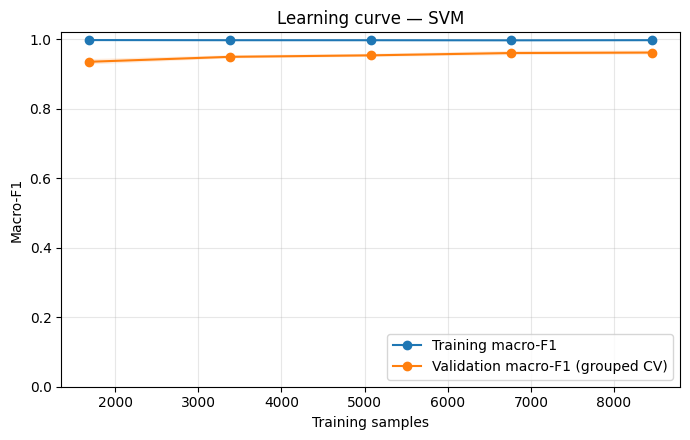

Final gap (train − validation): 3.56 points
Validation gain from the second-to-last to the last size: +0.14 points
→ Validation has levelled off: more of the same data will not help much; the main risk is the data domain (new people / backgrounds), not model size.


In [19]:

lc_estimator = MirrorAugmented(clone(candidates[best_name][0]), augment=USE_MIRROR_AUGMENTATION)
lc_estimator.set_params(**best_params)

sizes, train_scores, val_scores = learning_curve(
    lc_estimator, X_dev, y_dev, groups=g_dev, cv=cv,
    train_sizes=np.linspace(0.2, 1.0, 5), scoring="f1_macro",
    shuffle=True, random_state=RANDOM_STATE,
    n_jobs=(-1 if best_name == "SVM" else 1)
)
tr_mean, tr_std = train_scores.mean(axis=1), train_scores.std(axis=1)
va_mean, va_std = val_scores.mean(axis=1), val_scores.std(axis=1)

plt.figure(figsize=(7, 4.5))
plt.plot(sizes, tr_mean, "o-", label="Training macro-F1")
plt.fill_between(sizes, tr_mean - tr_std, tr_mean + tr_std, alpha=0.15)
plt.plot(sizes, va_mean, "o-", label="Validation macro-F1 (grouped CV)")
plt.fill_between(sizes, va_mean - va_std, va_mean + va_std, alpha=0.15)
plt.xlabel("Training samples"); plt.ylabel("Macro-F1"); plt.ylim(0, 1.02)
plt.title(f"Learning curve — {best_name}"); plt.grid(alpha=0.3); plt.legend(loc="lower right")
plt.tight_layout(); plt.show()

print(f"Final gap (train − validation): {(tr_mean[-1] - va_mean[-1])*100:.2f} points")
print(f"Validation gain from the second-to-last to the last size: {(va_mean[-1] - va_mean[-2])*100:+.2f} points")
if va_mean[-1] < 0.80 and tr_mean[-1] < 0.85:
    print("→ Both curves are low: underfitting.")
elif va_mean[-1] - va_mean[-2] > 0.01:
    print("→ Validation is still rising: more (and more varied) data should help.")
else:
    print("→ Validation has levelled off: more of the same data will not help much; "
          "the main risk is the data domain (new people / backgrounds), not model size.")

## 13. Test one image before opening the webcam

This checks the full OpenCV → MediaPipe → 63 features → classifier path with one Kaggle image and verifies that the file path (BGR→RGB) and the array path (used by the webcam) produce identical features. (An image from the training folders is only a pipeline sanity check, not an accuracy measurement.)

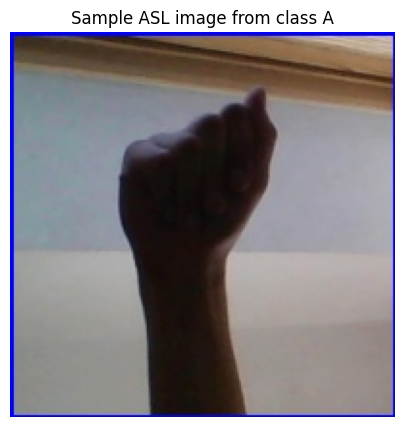

Training-path and webcam-path features identical: True
Mean difference between flipped and mirrored features: 0.057

Predicted ASL letter: A
Hand detected: 21 landmarks | Extracted features: 63

Top 5 predictions (SVM decision scores):
  A: 25.3254
  S: 24.3255
  T: 23.3225
  Y: 22.3163
  M: 21.3167


In [21]:

# Test SVM using one sample image from class A

test_image_path = next(
    path for path in sorted((TRAIN_DIR / "A").iterdir())
    if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS
)

# Read image
test_bgr = cv2.imread(str(test_image_path))

if test_bgr is None:
    raise ValueError("OpenCV could not read the selected test image.")

test_rgb = cv2.cvtColor(test_bgr, cv2.COLOR_BGR2RGB)

# Extract MediaPipe hand features
test_features, test_points = extract_features_from_rgb(test_rgb)

# Display image
plt.figure(figsize=(5, 5))
plt.imshow(test_rgb)
plt.title("Sample ASL image from class A")
plt.axis("off")
plt.show()

if test_features is None:
    print("MediaPipe did not detect a hand in this image.")
    print("Try another image.")

else:
    # Check feature extraction consistency
    file_features = extract_features_from_file(test_image_path)

    same = (
        file_features is not None
        and np.allclose(test_features, file_features)
    )

    print("Training-path and webcam-path features identical:", same)

    # Check mirror augmentation
    flipped_features, _ = extract_features_from_rgb(
        np.ascontiguousarray(test_rgb[:, ::-1])
    )

    if flipped_features is not None:
        diff = np.abs(
            flipped_features -
            mirror_features(test_features.reshape(1, -1))[0]
        ).mean()

        print(
            f"Mean difference between flipped and mirrored features: {diff:.3f}"
        )

    # Prepare features for SVM
    features = np.asarray(
        test_features, dtype=np.float32
    ).reshape(1, -1)

    # Predict ASL letter
    prediction = model.predict(features)[0]

    print("\nPredicted ASL letter:", prediction)
    print(
        "Hand detected:", len(test_points),
        "landmarks | Extracted features:", len(test_features)
    )

    # Get SVM decision scores (not probabilities)
    scores = np.asarray(
        model.decision_function(features)
    ).ravel()

    print("\nTop 5 predictions (SVM decision scores):")

    if len(scores) == len(model.classes_):
        top_order = np.argsort(scores)[::-1][:5]

        for i in top_order:
            print(
                f"  {model.classes_[i]}: {scores[i]:.4f}"
            )
    else:
        print("Top 5 scores are unavailable for this model.")


## 14. Calibrate confidence thresholds

The webcam logic only accepts a letter when the top probability (`MIN_SCORE`) and the gap to the runner-up (`MIN_MARGIN`) are high enough. The first version used fixed guesses (0.55 / 0.08). Probabilities from a Random Forest, Extra Trees and an SVM are scaled very differently, so the thresholds are chosen from **out-of-fold validation predictions on the development set**: the pair with the largest coverage whose accepted predictions are at least `TARGET_ACCEPTED_ACCURACY` accurate. The held-out test set is then only used to *check* them.

Real webcam probabilities can differ from dataset probabilities, so confirm with the live demo and edit `MIN_SCORE` / `MIN_MARGIN` if needed.

In [23]:

# Calibrate prediction confidence thresholds using SVM probabilities

TARGET_ACCEPTED_ACCURACY = 0.95

# Create a new estimator with probability support
proba_estimator = MirrorAugmented(
    clone(candidates[best_name][0]),
    augment=USE_MIRROR_AUGMENTATION
)

proba_estimator.set_params(**best_params)

# Enable probability estimates for SVM
if best_name == "SVM":
    proba_estimator.set_params(estimator__svc__probability=True)

# Generate out-of-fold probabilities on development data
oof_proba = cross_val_predict(
    proba_estimator,
    X_dev,
    y_dev,
    groups=g_dev,
    cv=cv,
    method="predict_proba",
    n_jobs=(-1 if best_name == "SVM" else 1)
)

class_order = np.array(sorted(set(y_dev)))


# Calculate prediction confidence and margins
def confidence_stats(probabilities, labels, classes):
    order = np.argsort(probabilities, axis=1)[:, ::-1]

    top = probabilities[np.arange(len(probabilities)), order[:, 0]]
    second = probabilities[np.arange(len(probabilities)), order[:, 1]]

    predicted = classes[order[:, 0]]
    correct = predicted == labels

    return top, top - second, correct


top_dev, margin_dev, correct_dev = confidence_stats(
    oof_proba,
    y_dev,
    class_order
)


# Find the best confidence thresholds
best_choice = None

for score_cut in np.arange(0.30, 0.91, 0.05):
    for margin_cut in (0.0, 0.05, 0.10, 0.15, 0.20):

        accepted = (
            (top_dev >= score_cut)
            & (margin_dev >= margin_cut)
        )

        if accepted.mean() < 0.20:
            continue

        accuracy = correct_dev[accepted].mean()

        if (
            accuracy >= TARGET_ACCEPTED_ACCURACY
            and (
                best_choice is None
                or accepted.mean() > best_choice[2]
            )
        ):
            best_choice = (
                float(score_cut),
                float(margin_cut),
                float(accepted.mean()),
                float(accuracy)
            )


# Select calibrated thresholds
if best_choice is None:
    print(
        "No threshold pair reached the target accuracy "
        "with at least 20% coverage."
    )

    MIN_SCORE = 0.55
    MIN_MARGIN = 0.08

else:
    MIN_SCORE = best_choice[0]
    MIN_MARGIN = best_choice[1]

    print(
        f"Calibrated thresholds: "
        f"MIN_SCORE={MIN_SCORE:.2f}, "
        f"MIN_MARGIN={MIN_MARGIN:.2f}"
    )

    print(
        f"Validation coverage: {best_choice[2] * 100:.1f}%"
    )

    print(
        f"Accepted accuracy: {best_choice[3] * 100:.2f}%"
    )


# Compare original and calibrated thresholds
for label, (s, m) in {
    "original 0.55/0.08": (0.55, 0.08),
    "calibrated": (MIN_SCORE, MIN_MARGIN)
}.items():

    accepted = (
        (top_dev >= s)
        & (margin_dev >= m)
    )

    accuracy = (
        correct_dev[accepted].mean()
        if accepted.any()
        else 0.0
    )

    print(
        f"Validation, {label:<20}: "
        f"coverage {accepted.mean() * 100:5.1f}% | "
        f"accepted accuracy {accuracy * 100:6.2f}%"
    )


# Train probability-enabled model on development data
print("\nTraining final probability-enabled model...")

proba_estimator.fit(X_dev, y_dev)

print("Final model training completed!")


# Evaluate on untouched test data
test_proba = proba_estimator.predict_proba(X_test)

test_classes = np.asarray(proba_estimator.classes_)

top_t, margin_t, correct_t = confidence_stats(
    test_proba,
    y_test,
    test_classes
)

accepted_t = (
    (top_t >= MIN_SCORE)
    & (margin_t >= MIN_MARGIN)
)

test_accuracy = (
    correct_t[accepted_t].mean()
    if accepted_t.any()
    else 0.0
)

print("\nFINAL TEST RESULTS")
print("------------------------------")

print(
    f"Test coverage: {accepted_t.mean() * 100:.1f}%"
)

print(
    f"Accepted prediction accuracy: "
    f"{test_accuracy * 100:.2f}%"
)

print(
    f"Overall test accuracy: "
    f"{correct_t.mean() * 100:.2f}%"
)

if correct_t.any():
    print(
        f"Median top probability (correct): "
        f"{np.median(top_t[correct_t]):.2f}"
    )

if (~correct_t).any():
    print(
        f"Median top probability (wrong): "
        f"{np.median(top_t[~correct_t]):.2f}"
    )


Calibrated thresholds: MIN_SCORE=0.30, MIN_MARGIN=0.00
Validation coverage: 99.3%
Accepted accuracy: 97.22%
Validation, original 0.55/0.08  : coverage  97.1% | accepted accuracy  98.30%
Validation, calibrated          : coverage  99.3% | accepted accuracy  97.22%

Training final probability-enabled model...
Final model training completed!

FINAL TEST RESULTS
------------------------------
Test coverage: 99.5%
Accepted prediction accuracy: 97.15%
Overall test accuracy: 96.77%
Median top probability (correct): 0.99
Median top probability (wrong): 0.57


In [35]:

import time

print("Test folder:", MY_TEST_DIR)
print("Folder exists:", MY_TEST_DIR.exists())

if MY_TEST_DIR.exists():
    image_files = []

    for letter in LETTERS:
        folder = MY_TEST_DIR / letter
        if folder.is_dir():
            image_files.extend([
                p for p in folder.iterdir()
                if p.suffix.lower() in IMAGE_EXTENSIONS
            ])

    print("Total images:", len(image_files))

    if image_files:
        start = time.time()
        sample_features = extract_features_from_file(image_files[0])
        print("First image:", image_files[0].name)
        print("Hand detected:", sample_features is not None)
        print("Processing time:", round(time.time() - start, 2), "seconds")
else:
    print("Create the my_webcam_test folder first.")


Test folder: /content/drive/MyDrive/ASL_Project/my_webcam_test
Folder exists: False
Create the my_webcam_test folder first.


## 15. Live webcam recognition and word builder

Run this cell after training has completed. In the Gradio app, click the webcam image/input and allow camera access in Chrome. If the camera is blocked, use the lock/site-settings icon beside the address bar, set Camera to Allow, reload the app, and select the webcam again.

Hold one static ASL handshape steady. After a letter is added, briefly remove your hand before showing the next letter. **Space**, **Delete** (backspace) and **Clear** are buttons.

Unchanged from the first version: the stable-frame logic, the lock/re-arm behaviour, landmark drawing and the buttons. Changed: the thresholds come from Section 14, features/detection use the corrected Section 7 code, and the webcam is **not** mirrored (the widget option differs between Gradio versions, so it is set defensively below).

## 16. Optional but strongly recommended: test on your own photos

A grouped split of the Kaggle data still cannot tell you how the model behaves for a *different person, background or camera*. To measure that honestly:

1. Take 10–20 photos per letter of your own hand (a phone or the laptop webcam, different lighting if possible; ideally also a friend's hand).
2. Put them in Google Drive as `MyDrive/ASL_Project/my_webcam_test/A/*.jpg`, `.../B/*.jpg`, … (folders only for the letters you captured).
3. Run this cell. These photos are **never** used for training or tuning; they are a genuine external test.

In [ ]:

import gradio as gr
import numpy as np
import cv2

# --------------------------------------------------
# 1. RECOGNITION SETTINGS
# --------------------------------------------------

MIN_SCORE = globals().get("MIN_SCORE", 0.55)
MIN_MARGIN = globals().get("MIN_MARGIN", 0.08)

STABLE_FRAMES = 6
NO_HAND_FRAMES_TO_REARM = 3

HAND_CONNECTIONS = [
    (0, 1), (1, 2), (2, 3), (3, 4),
    (0, 5), (5, 6), (6, 7), (7, 8),
    (5, 9), (9, 10), (10, 11), (11, 12),
    (9, 13), (13, 14), (14, 15), (15, 16),
    (13, 17), (17, 18), (18, 19), (19, 20),
    (0, 17)
]


# --------------------------------------------------
# 2. APP STATE
# --------------------------------------------------

def new_app_state():
    return {
        "word": "",
        "candidate": None,
        "stable_count": 0,
        "locked": False,
        "no_hand_count": 0
    }


# --------------------------------------------------
# 3. SVM SCORE CONVERSION
# --------------------------------------------------

def get_svm_scores(features):
    """
    Convert SVM decision scores into relative scores.
    These are NOT calibrated probabilities.
    """

    decision_scores = np.asarray(
        model.decision_function(features)
    )

    if decision_scores.ndim == 2:
        scores = decision_scores[0]
    else:
        scores = decision_scores

    # Multiclass SVC with OVR decision scores
    if len(scores) != len(model.classes_):
        raise ValueError(
            "SVM decision scores do not match the model classes. "
            "Check decision_function_shape='ovr'."
        )

    # Stable softmax for relative ranking
    scores = scores - np.max(scores)
    exp_scores = np.exp(scores)
    relative_scores = exp_scores / np.sum(exp_scores)

    return relative_scores


# --------------------------------------------------
# 4. LIVE RECOGNITION
# --------------------------------------------------

def live_recognition(frame, state):

    state = dict(state or new_app_state())

    if frame is None:
        return (
            None,
            "Waiting for camera...",
            "—",
            state["word"],
            "Start the webcam.",
            state
        )

    # Gradio webcam frame is RGB
    rgb = np.ascontiguousarray(
        np.asarray(frame, dtype=np.uint8)[:, :, :3]
    )

    annotated = rgb.copy()

    # Extract hand features using the same training function
    features, points_px = extract_features_from_rgb(rgb)

    # ----------------------------------------------
    # No hand detected
    # ----------------------------------------------

    if features is None:

        state["no_hand_count"] += 1
        state["candidate"] = None
        state["stable_count"] = 0

        if state["no_hand_count"] >= NO_HAND_FRAMES_TO_REARM:
            state["locked"] = False

        return (
            annotated,
            "No prediction",
            "—",
            state["word"],
            "No hand detected. Show your hand clearly.",
            state
        )

    state["no_hand_count"] = 0

    # ----------------------------------------------
    # Draw landmarks
    # ----------------------------------------------

    points = [
        (int(round(x)), int(round(y)))
        for x, y, _ in points_px
    ]

    for start, end in HAND_CONNECTIONS:
        cv2.line(
            annotated,
            points[start],
            points[end],
            (0, 255, 0),
            2
        )

    for point in points:
        cv2.circle(
            annotated,
            point,
            4,
            (255, 80, 0),
            -1
        )

    # ----------------------------------------------
    # SVM prediction
    # ----------------------------------------------

    features = np.asarray(
        features,
        dtype=np.float32
    ).reshape(1, -1)

    predicted_letter = str(model.predict(features)[0])

    # Use decision scores instead of predict_proba
    scores = get_svm_scores(features)

    order = np.argsort(scores)[::-1]

    best_index = int(order[0])
    best_score = float(scores[best_index])

    second_score = (
        float(scores[order[1]])
        if len(order) > 1 else 0.0
    )

    margin = best_score - second_score

    top_five = "\n".join(
        f"{model.classes_[int(i)]}: {scores[int(i)] * 100:.1f}%"
        for i in order[:5]
    )

    # ----------------------------------------------
    # Stable letter detection
    # ----------------------------------------------

    if state["locked"]:

        status = (
            "Letter added. Remove your hand briefly "
            "before entering the next letter."
        )

    elif best_score < MIN_SCORE or margin < MIN_MARGIN:

        state["candidate"] = None
        state["stable_count"] = 0

        status = "Uncertain handshape. Hold your hand steadily."

    else:

        if state["candidate"] == predicted_letter:
            state["stable_count"] += 1
        else:
            state["candidate"] = predicted_letter
            state["stable_count"] = 1

        if state["stable_count"] >= STABLE_FRAMES:

            state["word"] += predicted_letter
            state["locked"] = True

            status = (
                f"Added {predicted_letter}. "
                "Remove your hand for the next letter."
            )

        else:

            status = (
                f"Checking {predicted_letter}: "
                f"{state['stable_count']}/{STABLE_FRAMES} frames"
            )

    # ----------------------------------------------
    # Display results
    # ----------------------------------------------

    prediction_text = (
        f"Predicted: {predicted_letter}\n\n"
        f"TOP 5 RELATIVE SCORES\n{top_five}"
    )

    score_text = (
        f"Relative score: {best_score * 100:.1f}% | "
        f"Score margin: {margin * 100:.1f}%"
    )

    return (
        annotated,
        prediction_text,
        score_text,
        state["word"],
        status,
        state
    )


# --------------------------------------------------
# 5. WORD CONTROLS
# --------------------------------------------------

def add_space(state):

    state = dict(state or new_app_state())

    if state["word"] and not state["word"].endswith(" "):
        state["word"] += " "

    return state, state["word"], "Space added."


def backspace_word(state):

    state = dict(state or new_app_state())

    state["word"] = state["word"][:-1]
    state["locked"] = False
    state["candidate"] = None
    state["stable_count"] = 0

    return state, state["word"], "Last character removed."


def clear_word(state):

    state = new_app_state()

    return state, "", "Text cleared."


# --------------------------------------------------
# 6. WEBCAM INPUT
# --------------------------------------------------

def make_webcam_input():

    base = {
        "sources": ["webcam"],
        "type": "numpy",
        "streaming": True,
        "label": "Live ASL Webcam"
    }

    attempts = []

    if hasattr(gr, "WebcamOptions"):
        attempts.append({
            "webcam_options": gr.WebcamOptions(mirror=False)
        })

    attempts.append({"mirror_webcam": False})
    attempts.append({})

    for extra in attempts:

        try:
            widget = gr.Image(**base, **extra)
            print("Webcam configured successfully.")
            return widget

        except TypeError:
            continue

    raise RuntimeError(
        "Could not create webcam input. Check your Gradio version."
    )


# --------------------------------------------------
# 7. GRADIO APPLICATION
# --------------------------------------------------

with gr.Blocks(title="ASL Alphabet Recognition") as asl_app:

    gr.Markdown(
        """
        # ASL Alphabet Recognition

        ### Real-Time Sign Language Detection

        Show one ASL handshape at a time.
        Hold your hand steady until a letter is recognized.
        Remove your hand before entering the next letter.
        """
    )

    app_state = gr.State(new_app_state())

    with gr.Row():

        webcam = make_webcam_input()

        annotated_output = gr.Image(
            label="Live Hand Landmark Detection"
        )

    with gr.Row():

        prediction_output = gr.Textbox(
            label="SVM Prediction",
            lines=7,
            interactive=False
        )

        score_output = gr.Textbox(
            label="Relative Model Scores",
            interactive=False
        )

    word_output = gr.Textbox(
        label="Recognized Word / Sentence",
        lines=2,
        interactive=False
    )

    status_output = gr.Textbox(
        label="Recognition Status",
        interactive=False
    )

    with gr.Row():

        space_button = gr.Button("Space")

        backspace_button = gr.Button(
            "Delete Last Character"
        )

        clear_button = gr.Button(
            "Clear",
            variant="stop"
        )

    webcam.stream(
        fn=live_recognition,
        inputs=[webcam, app_state],
        outputs=[
            annotated_output,
            prediction_output,
            score_output,
            word_output,
            status_output,
            app_state
        ],
        stream_every=0.25,
        concurrency_limit=1
    )

    space_button.click(
        fn=add_space,
        inputs=app_state,
        outputs=[
            app_state,
            word_output,
            status_output
        ]
    )

    backspace_button.click(
        fn=backspace_word,
        inputs=app_state,
        outputs=[
            app_state,
            word_output,
            status_output
        ]
    )

    clear_button.click(
        fn=clear_word,
        inputs=app_state,
        outputs=[
            app_state,
            word_output,
            status_output
        ]
    )


# --------------------------------------------------
# 8. START APPLICATION
# --------------------------------------------------

asl_app.queue().launch(
    share=True,
    debug=True
)


Webcam configured successfully.
Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://105004ce533dc1787e.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 17. Project summary and limitations

- **Input:** Kaggle ASL Alphabet images (letters A–Z; `del`, `nothing`, `space` folders deliberately not trained) and live webcam frames.
- **OpenCV:** reads dataset images, converts BGR to RGB, pads and retries failed detections, and draws landmarks on webcam frames.
- **MediaPipe:** detects one hand and returns 21 landmarks (detector file only; not an ASL classifier).
- **Features:** 63 values = pixel-space, wrist-relative, hand-size-normalized x/y/z, identical for training and webcam.
- **Training:** Random Forest, Extra Trees and SVM are tuned with grouped, stratified cross-validation on a development set and compared by macro-F1 and balanced accuracy; the winner is trained from scratch and evaluated once on frame blocks held out from training.
- **Evaluation:** training / validation / test metrics, classification report, confusion matrices, per-letter results, learning curves, leakage diagnostic, calibrated confidence thresholds, optional external test on your own photos.
- **Recognition:** the webcam uses the newly trained classifier, stable-frame confirmation, lock/re-arm and Space / Delete / Clear.

### Limitations (say these in the demonstration)
1. Static alphabet handshapes only. J and Z involve movement; here they are judged from one frame, so their scores describe handshape only.
2. The Kaggle images come from very few signers with a uniform background and camera. Grouped splitting removes near-duplicate leakage but cannot prove accuracy for other people; use Section 16 for that.
3. No "nothing" class is trained: a non-letter hand pose will be mapped to the closest letter unless confidence thresholds reject it.
4. Webcam performance depends on lighting, hand distance, camera permission in the browser, and the Gradio app staying open.
5. All numbers in this notebook are computed when you run it. None are pre-filled.